# Bài 2 – Time series: Dự báo nồng độ CO₂ khí quyển (Mauna Loa)
**Môn:** Nền tảng lập trình cho phân tích và trực quan dữ liệu – HK 261 (2026–2027) · **GV:** Lê Thành Sách
**Nhóm:** BugIsFeature · **Sinh viên:** Nguyễn Thị Cẩm Vân · **MSSV:** 2570803
**Hình thức:** cá nhân · **Loại dữ liệu:** Time series (tự chọn)

## 1. Mô tả bài toán và tập dữ liệu
- **Nguồn:** `statsmodels.datasets.co2` – đo CO₂ hàng tuần tại Mauna Loa (Scripps), 03/1958 – 12/2001, **2284 điểm**, có **59 giá trị thiếu**.
- **Đặc điểm:** *xu hướng tăng dài hạn* + *mùa vụ hàng năm* (chu kỳ 52 tuần).
- **Bài toán:** dự báo **12 tuần tới** (horizon h=12) – hồi quy.
- **Nguyên tắc:** chia train/val/test **theo thời gian** (không shuffle), mọi biến đổi chỉ dùng thông tin quá khứ để tránh data leakage.
- **Metric:** MAE, RMSE, MAPE.

In [1]:
import warnings, sys
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px, plotly.graph_objects as go, plotly.io as pio
from IPython.display import display, Markdown
if "google.colab" not in sys.modules:
    pio.renderers.default = "notebook_connected"
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42
def note(text):
    """Hiển thị caption/kết luận (Markdown) sinh từ số liệu thực tế."""
    display(Markdown(text))

import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
H = 12   # horizon (tuần)

In [2]:
co2 = sm.datasets.co2.load_pandas().data["co2"]
print(co2.shape, "| thiếu:", co2.isna().sum(), "| tần suất:", pd.infer_freq(co2.index))
co2.head()

(2284,) | thiếu: 59 | tần suất: W-SAT


1958-03-29    316.1
1958-04-05    317.3
1958-04-12    317.6
1958-04-19    317.5
1958-04-26    316.4
Freq: W-SAT, Name: co2, dtype: float64

## 2. Khám phá dữ liệu (EDA)
### 2.1 Chuỗi gốc và missing

In [3]:
miss_idx = co2[co2.isna()].index
fig = go.Figure()
fig.add_trace(go.Scatter(x=co2.index, y=co2.values, name="CO₂ (ppm)", line=dict(width=1.2)))
fig.add_trace(go.Scatter(x=miss_idx, y=[co2.min()]*len(miss_idx), mode="markers", name="Ngày thiếu", marker=dict(color="red", size=4)))
fig.update_layout(title="CO₂ hàng tuần tại Mauna Loa", yaxis_title="ppm", height=420)
fig.show()
gaps = (pd.Series(miss_idx).diff() != pd.Timedelta(weeks=1)).sum()
note(f"**Kết luận:** CO₂ tăng từ **{co2.dropna().iloc[0]:.1f}** lên **{co2.dropna().iloc[-1]:.1f} ppm** (+{co2.dropna().iloc[-1]-co2.dropna().iloc[0]:.1f}) trong 44 năm, kèm dao động mùa vụ đều đặn. "
     f"Có **{len(miss_idx)}** tuần thiếu ({len(miss_idx)/len(co2):.1%}) tạo thành **{gaps}** khoảng trống.")

**Kết luận:** CO₂ tăng từ **316.1** lên **371.5 ppm** (+55.4) trong 44 năm, kèm dao động mùa vụ đều đặn. Có **59** tuần thiếu (2.6%) tạo thành **22** khoảng trống.

### 2.2 Phân rã xu hướng – mùa vụ – phần dư

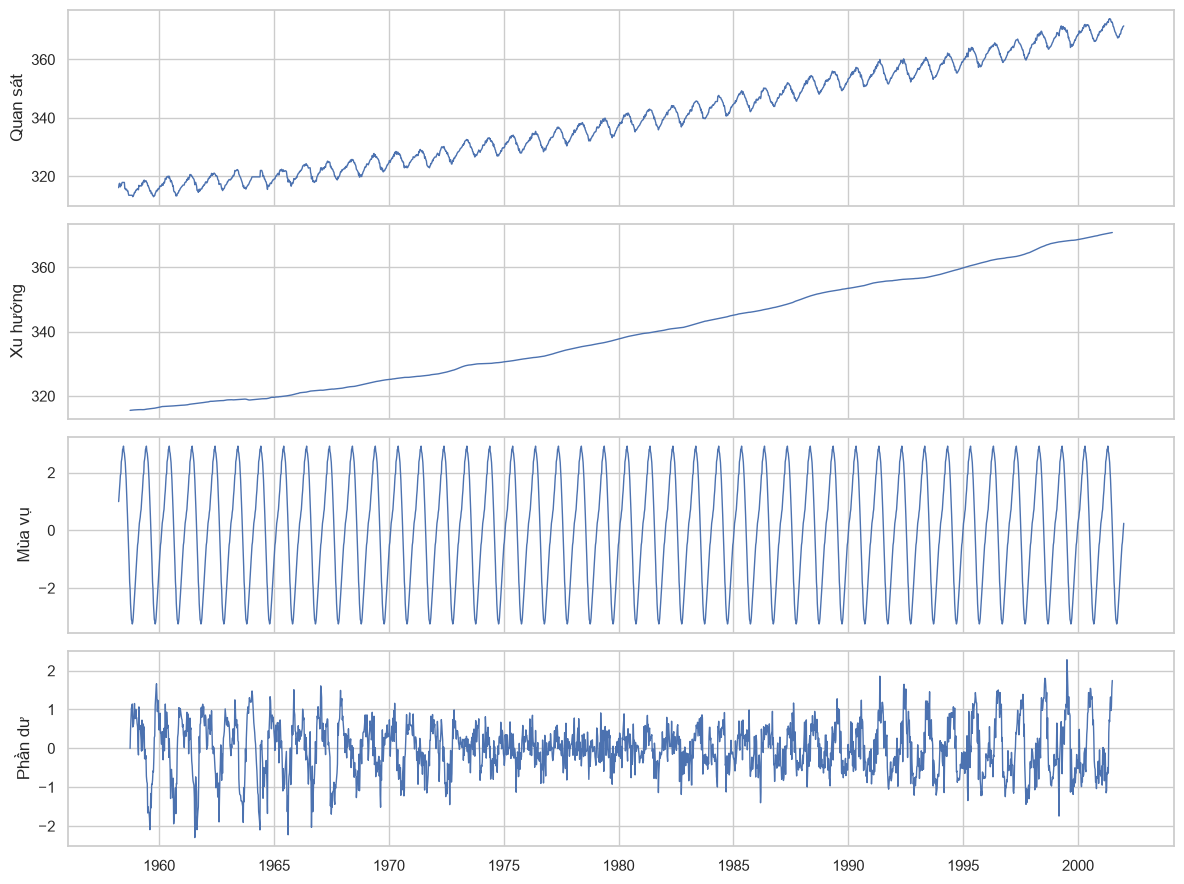

**Kết luận:** biên độ mùa vụ ≈ **6.2 ppm**, xu hướng tăng ≈ **1.29 ppm/năm**; mùa vụ chỉ giải thích **1.3%** phương sai so với xu hướng. => Mô hình phải *ngoại suy được xu hướng tăng* thì mới dự báo tốt.

In [4]:
co2_ff = co2.ffill().bfill()          # chỉ để phân rã/EDA; xử lý chính thức ở mục 3
dec = seasonal_decompose(co2_ff, model="additive", period=52)
fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for a, (t, s) in zip(ax, [("Quan sát", dec.observed), ("Xu hướng", dec.trend), ("Mùa vụ", dec.seasonal), ("Phần dư", dec.resid)]):
    a.plot(s, lw=1); a.set_ylabel(t)
plt.tight_layout(); plt.show()
amp = dec.seasonal.max() - dec.seasonal.min()
trend_per_year = (dec.trend.dropna().iloc[-1] - dec.trend.dropna().iloc[0]) / (len(dec.trend.dropna()) / 52)
var_share = dec.seasonal.var() / co2_ff.var()
note(f"**Kết luận:** biên độ mùa vụ ≈ **{amp:.1f} ppm**, xu hướng tăng ≈ **{trend_per_year:.2f} ppm/năm**; mùa vụ chỉ giải thích **{var_share:.1%}** phương sai so với xu hướng. "
     "=> Mô hình phải *ngoại suy được xu hướng tăng* thì mới dự báo tốt.")

### 2.3 Phát hiện outlier trên phần dư mùa vụ

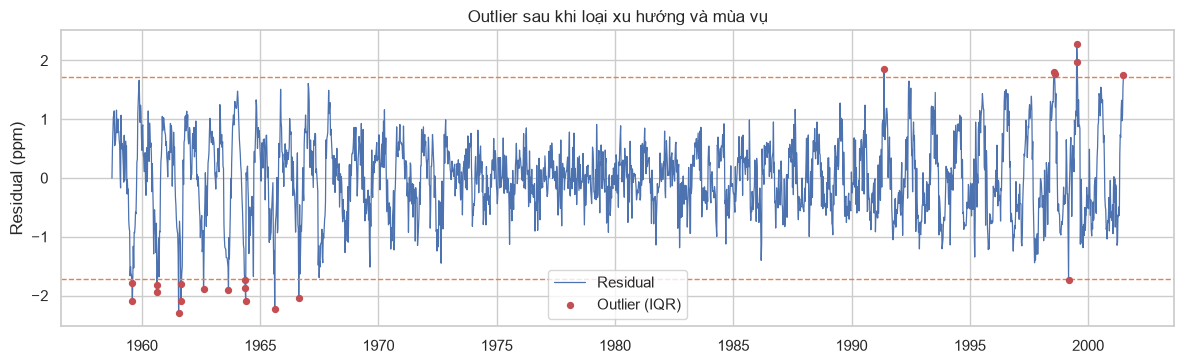

**Kết luận:** phát hiện **21** điểm bất thường (0.94%) ngoài khoảng IQR [-1.72, 1.72] ppm. Không xóa các điểm này vì có thể là biến động khí quyển thật; mô hình cây và metric MAE tương đối bền với outlier. Phần missing vẫn được forward-fill ở bước chuẩn bị dữ liệu.

In [5]:
resid = dec.resid.dropna()
q1, q3 = resid.quantile([.25, .75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = resid[(resid < lower) | (resid > upper)]
plt.figure(figsize=(12, 3.8))
plt.plot(resid, color="#4c72b0", lw=.9, label="Residual")
plt.scatter(outliers.index, outliers, color="#c44e52", s=18, label="Outlier (IQR)", zorder=3)
plt.axhline(lower, color="#dd8452", ls="--", lw=1)
plt.axhline(upper, color="#dd8452", ls="--", lw=1)
plt.title("Outlier sau khi loại xu hướng và mùa vụ")
plt.ylabel("Residual (ppm)"); plt.legend(); plt.tight_layout(); plt.show()
note(f"**Kết luận:** phát hiện **{len(outliers)}** điểm bất thường ({len(outliers)/len(resid):.2%}) ngoài khoảng IQR [{lower:.2f}, {upper:.2f}] ppm. "
    "Không xóa các điểm này vì có thể là biến động khí quyển thật; mô hình cây và metric MAE tương đối bền với outlier. Phần missing vẫn được forward-fill ở bước chuẩn bị dữ liệu.")

### 2.4 Mùa vụ theo tháng và tự tương quan

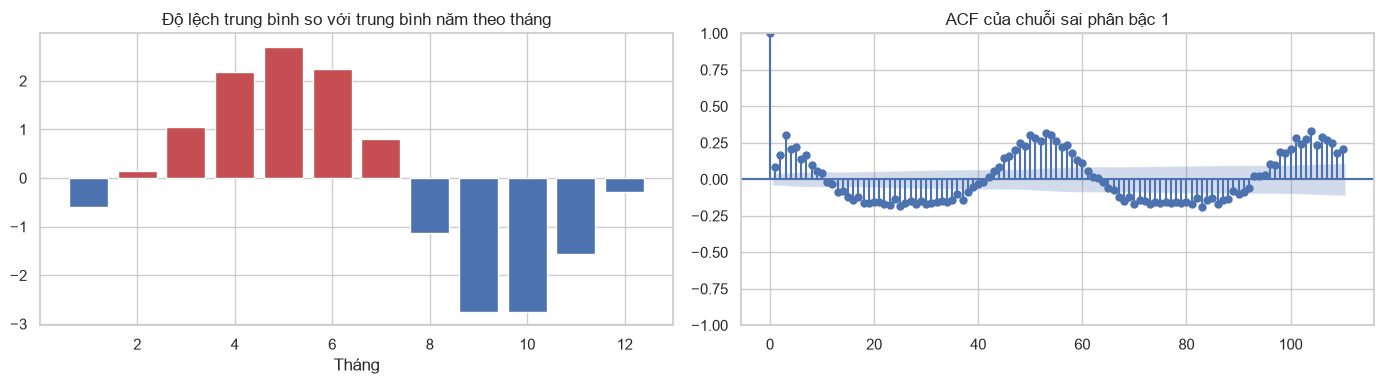

**Kết luận:** CO₂ đạt đỉnh vào tháng **5** (+2.70 ppm) và đáy vào tháng **10** (-2.75 ppm) – phù hợp chu kỳ quang hợp của thực vật bán cầu Bắc. ACF có đỉnh quanh lag 52 xác nhận chu kỳ năm -> nên đưa **lag 52** và **sin/cos tuần trong năm** vào feature.

In [6]:
dev = co2_ff - co2_ff.groupby(co2_ff.index.year).transform("mean")
m = dev.groupby(dev.index.month).mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(m.index, m.values, color=np.where(m.values > 0, "#c44e52", "#4c72b0")); ax[0].set_title("Độ lệch trung bình so với trung bình năm theo tháng"); ax[0].set_xlabel("Tháng")
plot_acf(co2_ff.diff().dropna(), lags=110, ax=ax[1]); ax[1].set_title("ACF của chuỗi sai phân bậc 1")
plt.tight_layout(); plt.show()
note(f"**Kết luận:** CO₂ đạt đỉnh vào tháng **{m.idxmax()}** (+{m.max():.2f} ppm) và đáy vào tháng **{m.idxmin()}** ({m.min():.2f} ppm) – phù hợp chu kỳ quang hợp của thực vật bán cầu Bắc. ACF có đỉnh quanh lag 52 xác nhận chu kỳ năm -> nên đưa **lag 52** và **sin/cos tuần trong năm** vào feature.")

## 3. Chuẩn bị dữ liệu
1. **Missing:** *forward-fill* (chỉ dùng quá khứ, không rò rỉ tương lai; nội suy tuyến tính sẽ dùng giá trị tương lai).
2. **Feature:** lag 1,2,3,4,8,12,26,52; trung bình trượt 4/12/52 tuần (dịch 0, tính trên quá khứ đến thời điểm t); sin/cos tuần trong năm; chỉ số thời gian `t` (xu hướng).
3. **Target:** giá trị tại **t+12**.
4. **Split theo thời gian:** 70% train / 15% val / 15% test (không shuffle). Với horizon h, hàng cuối cùng của mỗi tập được loại để target không chồng sang tập sau.
5. **Scaling:** StandardScaler fit trên train (cho mô hình tuyến tính).

In [7]:
y = co2.ffill().bfill()
feat = pd.DataFrame(index=y.index)
for l in [1, 2, 3, 4, 8, 12, 26, 52]:
    feat[f"lag_{l}"] = y.shift(l - 1)           # lag_1 = giá trị hiện tại (tại t)
for w in [4, 12, 52]:
    feat[f"roll_mean_{w}"] = y.rolling(w).mean()
woy = y.index.isocalendar().week.astype(int).clip(upper=52).values
feat["sin52"] = np.sin(2 * np.pi * woy / 52); feat["cos52"] = np.cos(2 * np.pi * woy / 52)
feat["t"] = np.arange(len(y))
target = y.shift(-H)                            # giá trị 12 tuần sau
data = feat.assign(target=target, current=y).dropna()
n = len(data); i1, i2 = int(n * .70), int(n * .85)
train = data.iloc[:i1 - H]; val = data.iloc[i1:i2 - H]; test = data.iloc[i2:]
print({k: (len(v), str(v.index[0].date()), str(v.index[-1].date())) for k, v in dict(train=train, val=val, test=test).items()})
FEATS = [c for c in data.columns if c not in ("target", "current")]

{'train': (1542, '1959-03-21', '1988-10-01'), 'val': (321, '1988-12-31', '1995-02-18'), 'test': (334, '1995-05-20', '2001-10-06')}


In [8]:
fig = go.Figure()
for nm, d, col in [("Train", train, "#4c72b0"), ("Validation", val, "#dd8452"), ("Test", test, "#c44e52")]:
    fig.add_trace(go.Scatter(x=d.index, y=d["current"], name=nm, line=dict(color=col)))
fig.update_layout(title="Chia dữ liệu theo thời gian (không shuffle)", yaxis_title="ppm", height=380); fig.show()
note(f"**Kết luận:** test ({test.index[0].year}–{test.index[-1].year}) nằm hoàn toàn *sau* train, nên đánh giá mô phỏng đúng tình huống dự báo thực tế. "
     f"Giá trị CO₂ trên test (trung bình {test['current'].mean():.1f}) cao hơn hẳn train ({train['current'].mean():.1f}) -> mô hình bị thử thách khi **ngoại suy xu hướng**.")

**Kết luận:** test (1995–2001) nằm hoàn toàn *sau* train, nên đánh giá mô phỏng đúng tình huống dự báo thực tế. Giá trị CO₂ trên test (trung bình 366.1) cao hơn hẳn train (330.8) -> mô hình bị thử thách khi **ngoại suy xu hướng**.

## 4. Mô hình hóa
| Mô hình | Ý tưởng |
|---|---|
| Naive | dự báo = giá trị hiện tại |
| Seasonal naive | = giá trị cùng thời điểm năm trước của mốc dự báo (t+12−52) |
| Ridge (level) | hồi quy tuyến tính dự báo trực tiếp *mức* CO₂ |
| RandomForest (level) | cây quyết định dự báo *mức* – không ngoại suy được |
| HistGB (level) | tương tự với boosting |
| **RandomForest (delta)** | dự báo **mức thay đổi** `y[t+12] − y[t]` rồi cộng lại giá trị hiện tại |
| **HistGB (delta)** | tương tự |
| **Ridge (delta)** | tương tự |

In [9]:
def metrics(name, yt, yp):
    return dict(model=name, MAE=mean_absolute_error(yt, yp),
                RMSE=np.sqrt(mean_squared_error(yt, yp)), MAPE_pct=100 * mean_absolute_percentage_error(yt, yp))

# Chọn alpha của Ridge trên VALIDATION
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
best_a = min([0.01, 0.1, 1, 10, 100],
             key=lambda a: mean_absolute_error(val["target"], make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(train[FEATS], train["target"]).predict(val[FEATS])))
print("alpha Ridge chọn từ validation:", best_a)

def fit_predict(make, delta):
    Xtr, Xte = train[FEATS], test[FEATS]
    ytr = train["target"] - train["current"] if delta else train["target"]
    p = make().fit(Xtr, ytr).predict(Xte)
    return p + test["current"].values if delta else p

makers = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=best_a)),
    "RandomForest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "HistGB": lambda: HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
preds = {"Naive": test["current"].values}
sn = y.shift(52 - H).reindex(test.index)       # giá trị tại (t+12)-52 = đã biết tại thời điểm t
preds["Seasonal naive"] = (sn.fillna(test["current"])).values + 0
# Seasonal naive + drift để công bằng: cộng tăng trưởng 52 tuần gần nhất
preds["Seasonal naive + drift"] = preds["Seasonal naive"] + (test["current"] - y.shift(52).reindex(test.index)).values
for nm, mk in makers.items():
    preds[f"{nm} (level)"] = fit_predict(mk, delta=False)
    preds[f"{nm} (delta)"] = fit_predict(mk, delta=True)
res = pd.DataFrame([metrics(k, test["target"], v) for k, v in preds.items()]).set_index("model").sort_values("MAE")
display(res.round(3).style.background_gradient(cmap="Greens_r", subset=["MAE", "RMSE", "MAPE_pct"]))

alpha Ridge chọn từ validation: 0.1


,MAE,RMSE,MAPE_pct
model,,,
RandomForest (delta),0.555000,0.709000,0.151000
HistGB (delta),0.586000,0.735000,0.160000
Ridge (delta),0.597000,0.757000,0.163000
Ridge (level),0.601000,0.759000,0.164000
Seasonal naive + drift,0.651000,0.825000,0.178000
Seasonal naive,1.684000,1.881000,0.460000
Naive,2.769000,3.071000,0.757000
HistGB (level),15.050000,15.410000,4.099000
RandomForest (level),16.023000,16.409000,4.363000


### 4.1 So sánh mô hình: dự báo *level* và *delta*

In [10]:
fig = px.bar(res.reset_index(), x="model", y="MAE", color="MAE", color_continuous_scale="RdYlGn_r",
             title="MAE trên tập test theo mô hình (horizon 12 tuần)", height=430)
fig.update_layout(xaxis_title="", yaxis_title="MAE (ppm)"); fig.show()
b, w = res.index[0], res.index[-1]
rf_l, rf_d = res.loc["RandomForest (level)", "MAE"], res.loc["RandomForest (delta)", "MAE"]
note(f"**Kết luận:** mô hình tốt nhất là **{b}** (MAE **{res.iloc[0].MAE:.3f}** ppm, MAPE {res.iloc[0].MAPE_pct:.3f}%); kém nhất: **{w}** (MAE {res.iloc[-1].MAE:.3f}). "
     f"Cùng một RandomForest, đổi mục tiêu từ *level* sang *delta* làm MAE giảm **{rf_l:.3f} → {rf_d:.3f}** (giảm {(1-rf_d/rf_l):.0%}) – vì cây không thể dự đoán giá trị lớn hơn mọi giá trị đã thấy trong train, còn dự báo *mức thay đổi* thì không bị giới hạn. "
     f"So với Naive (MAE {res.loc['Naive','MAE']:.3f}), mô hình tốt nhất giảm sai số {(1-res.iloc[0].MAE/res.loc['Naive','MAE']):.0%}.")

**Kết luận:** mô hình tốt nhất là **RandomForest (delta)** (MAE **0.555** ppm, MAPE 0.151%); kém nhất: **RandomForest (level)** (MAE 16.023). Cùng một RandomForest, đổi mục tiêu từ *level* sang *delta* làm MAE giảm **16.023 → 0.555** (giảm 97%) – vì cây không thể dự đoán giá trị lớn hơn mọi giá trị đã thấy trong train, còn dự báo *mức thay đổi* thì không bị giới hạn. So với Naive (MAE 2.769), mô hình tốt nhất giảm sai số 80%.

### 4.2 Dự báo so với thực tế (tập test)

In [11]:
best_nm = res.index[0]
fig = go.Figure()
fig.add_trace(go.Scatter(x=test.index, y=test["target"], name="Thực tế (t+12)", line=dict(color="black", width=2)))
for nm, col in [(best_nm, "#2ca02c"), ("RandomForest (level)", "#d62728"), ("Naive", "#7f7f7f")]:
    fig.add_trace(go.Scatter(x=test.index, y=preds[nm], name=nm, line=dict(color=col, dash="dot" if nm != best_nm else "solid")))
fig.update_layout(title="Dự báo 12 tuần tới vs thực tế", yaxis_title="ppm", height=440); fig.show()
err_rf = test["target"].values - preds["RandomForest (level)"]
note(f"**Kết luận:** RandomForest (level) dự báo **thấp hơn thực tế một cách hệ thống** (sai số trung bình {err_rf.mean():+.2f} ppm, nghĩa là luôn thấp hơn), "
     f"đường dự báo bị 'phẳng' ở mức tối đa đã thấy trong train ({train['target'].max():.1f} ppm). Mô hình **{best_nm}** bám sát đường thực tế cả xu hướng lẫn mùa vụ (sai số trung bình {(test['target'].values - preds[best_nm]).mean():+.3f} ppm).")

**Kết luận:** RandomForest (level) dự báo **thấp hơn thực tế một cách hệ thống** (sai số trung bình +16.02 ppm, nghĩa là luôn thấp hơn), đường dự báo bị 'phẳng' ở mức tối đa đã thấy trong train (354.5 ppm). Mô hình **RandomForest (delta)** bám sát đường thực tế cả xu hướng lẫn mùa vụ (sai số trung bình -0.173 ppm).

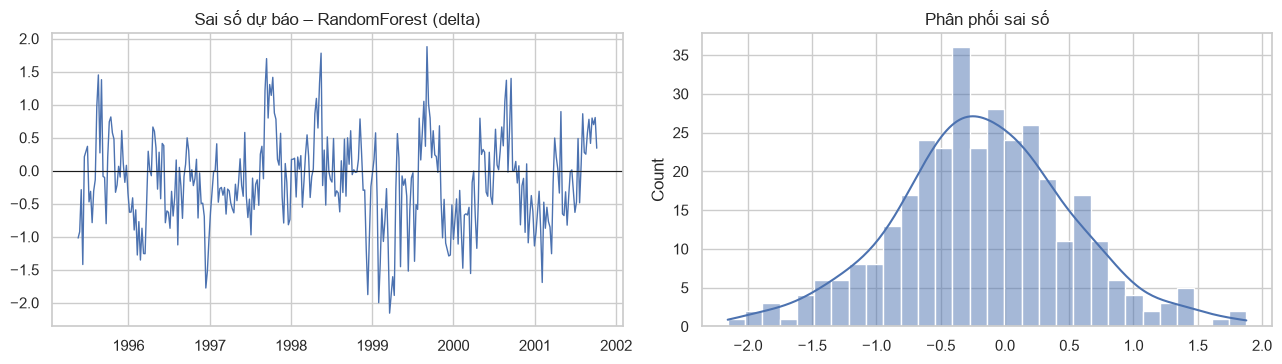

**Kết luận:** sai số khá cân quanh 0 (độ lệch chuẩn 0.689 ppm). Tháng khó dự báo nhất là **tháng 12** (|sai số| TB 0.797), dễ nhất là **tháng 10** (0.406) – thường là các tháng chuyển pha mùa vụ (đỉnh/đáy) nên khó hơn.

In [12]:
# Phân tích sai số theo thời gian của mô hình tốt nhất
e = pd.Series(test["target"].values - preds[best_nm], index=test.index)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(e, lw=1); ax[0].axhline(0, color="k", lw=.8); ax[0].set_title(f"Sai số dự báo – {best_nm}")
sns.histplot(e, bins=30, ax=ax[1], kde=True); ax[1].set_title("Phân phối sai số")
plt.tight_layout(); plt.show()
by_season = e.abs().groupby(e.index.month).mean()
note(f"**Kết luận:** sai số khá cân quanh 0 (độ lệch chuẩn {e.std():.3f} ppm). Tháng khó dự báo nhất là **tháng {by_season.idxmax()}** (|sai số| TB {by_season.max():.3f}), "
     f"dễ nhất là **tháng {by_season.idxmin()}** ({by_season.min():.3f}) – thường là các tháng chuyển pha mùa vụ (đỉnh/đáy) nên khó hơn.")

### 4.3 Độ ổn định theo horizon (mở rộng)
Kiểm tra mô hình tốt nhất khi horizon dài hơn (4, 12, 26, 52 tuần) so với Naive.

In [13]:
def run_horizon(h):
    tg = y.shift(-h)
    d = feat.assign(target=tg, current=y).dropna()
    n = len(d); a, b2 = int(n * .70), int(n * .85)
    tr, te = d.iloc[:a - h], d.iloc[b2:]
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
    m.fit(tr[FEATS], tr["target"] - tr["current"])
    p = m.predict(te[FEATS]) + te["current"].values
    return dict(horizon_weeks=h, naive_MAE=mean_absolute_error(te["target"], te["current"]),
                RF_delta_MAE=mean_absolute_error(te["target"], p))
hz = pd.DataFrame([run_horizon(h) for h in [4, 12, 26, 52]]).set_index("horizon_weeks")
display(hz.round(3))
fig = px.line(hz.reset_index().melt("horizon_weeks"), x="horizon_weeks", y="value", color="variable", markers=True,
              title="MAE theo horizon: Naive vs RandomForest (delta)", labels={"value": "MAE (ppm)"}); fig.show()
note(f"**Kết luận:** sai số của cả hai tăng theo horizon, nhưng RF (delta) tăng chậm hơn: ở h=52, MAE **{hz.loc[52,'RF_delta_MAE']:.3f}** vs Naive **{hz.loc[52,'naive_MAE']:.3f}** "
     f"(giảm {(1-hz.loc[52,'RF_delta_MAE']/hz.loc[52,'naive_MAE']):.0%}). Mô hình tận dụng được mùa vụ nên lợi thế so với Naive lớn dần khi dự báo xa.")

,naive_MAE,RF_delta_MAE
horizon_weeks,,
4,1.108,0.454
12,2.769,0.557
26,3.733,0.687
52,1.678,0.945


**Kết luận:** sai số của cả hai tăng theo horizon, nhưng RF (delta) tăng chậm hơn: ở h=52, MAE **0.945** vs Naive **1.678** (giảm 44%). Mô hình tận dụng được mùa vụ nên lợi thế so với Naive lớn dần khi dự báo xa.

## 5. Tổng kết và mở rộng

In [14]:
tab = "\n".join(f"| {i} | {r.MAE:.3f} | {r.RMSE:.3f} | {r.MAPE_pct:.3f} |" for i, r in res.iterrows())
note(f"""
### Kết quả (test, horizon {H} tuần, {len(test)} mẫu)
| Mô hình | MAE | RMSE | MAPE % |
|---|---|---|---|
{tab}

- **Mô hình tốt nhất:** {res.index[0]} – MAE {res.iloc[0].MAE:.3f} ppm, so với Naive {res.loc['Naive','MAE']:.3f}.
- **Bài học chính:** với chuỗi có xu hướng, mô hình cây dự báo *mức* sẽ thất bại khi ngoại suy (MAE {rf_l:.3f}); dự báo *mức thay đổi* (delta) giải quyết được (MAE {rf_d:.3f}).
- Split theo thời gian + forward-fill bảo đảm không rò rỉ tương lai.

### Hạn chế
- Chỉ một chuỗi đơn biến; chưa dùng mô hình thống kê chuyên dụng (SARIMA, ETS, Prophet) để đối chiếu.
- Một lần chia train/val/test; chưa dùng walk-forward CV đầy đủ. Siêu tham số cây để mặc định.
- Dữ liệu dừng ở 2001 – chưa phản ánh giai đoạn tăng tốc sau đó.

### Hướng mở rộng
- So sánh với SARIMA/ETS; walk-forward `TimeSeriesSplit`; khoảng tin cậy dự báo (quantile regression).
- Thêm biến ngoại sinh (ENSO, phát thải) và áp dụng cho chuỗi cập nhật mới nhất của NOAA.
""")


### Kết quả (test, horizon 12 tuần, 334 mẫu)
| Mô hình | MAE | RMSE | MAPE % |
|---|---|---|---|
| RandomForest (delta) | 0.555 | 0.709 | 0.151 |
| HistGB (delta) | 0.586 | 0.735 | 0.160 |
| Ridge (delta) | 0.597 | 0.757 | 0.163 |
| Ridge (level) | 0.601 | 0.759 | 0.164 |
| Seasonal naive + drift | 0.651 | 0.825 | 0.178 |
| Seasonal naive | 1.684 | 1.881 | 0.460 |
| Naive | 2.769 | 3.071 | 0.757 |
| HistGB (level) | 15.050 | 15.410 | 4.099 |
| RandomForest (level) | 16.023 | 16.409 | 4.363 |

- **Mô hình tốt nhất:** RandomForest (delta) – MAE 0.555 ppm, so với Naive 2.769.
- **Bài học chính:** với chuỗi có xu hướng, mô hình cây dự báo *mức* sẽ thất bại khi ngoại suy (MAE 16.023); dự báo *mức thay đổi* (delta) giải quyết được (MAE 0.555).
- Split theo thời gian + forward-fill bảo đảm không rò rỉ tương lai.

### Hạn chế
- Chỉ một chuỗi đơn biến; chưa dùng mô hình thống kê chuyên dụng (SARIMA, ETS, Prophet) để đối chiếu.
- Một lần chia train/val/test; chưa dùng walk-forward CV đầy đủ. Siêu tham số cây để mặc định.
- Dữ liệu dừng ở 2001 – chưa phản ánh giai đoạn tăng tốc sau đó.

### Hướng mở rộng
- So sánh với SARIMA/ETS; walk-forward `TimeSeriesSplit`; khoảng tin cậy dự báo (quantile regression).
- Thêm biến ngoại sinh (ENSO, phát thải) và áp dụng cho chuỗi cập nhật mới nhất của NOAA.
